# Food Calorie Prediction from Images

This notebook implements a Convolutional Neural Network (CNN) model to predict the calorie content of food items from images. We'll use the NutritionVerse-Real dataset, which contains 889 images of 251 distinct dishes across 45 unique food types.

## Project Structure
1. Dataset Download & Exploration
2. Data Preprocessing & Augmentation 
3. CNN Model Architecture Design
4. Model Training & Evaluation
5. Gradio Interface Integration

Let's begin!

## 1. Environment Setup & Dataset Download

First, let's install the necessary packages and download the dataset from Kaggle.

In [1]:
# Install required packages
!pip install tensorflow numpy pandas matplotlib seaborn scikit-learn kaggle gradio pillow

# Set up Kaggle API credentials (you need to upload your kaggle.json file)
import os
import json

# Uncomment the following if you're in Google Colab
# uploaded = files.upload()  # Upload kaggle.json
# os.makedirs('/root/.kaggle', exist_ok=True)
# with open('/root/.kaggle/kaggle.json', 'w') as f:
#     f.write(json.dumps(json.loads(next(iter(uploaded.values())).decode())))
# os.chmod('/root/.kaggle/kaggle.json', 600)

# For local environment, ensure your kaggle.json is in ~/.kaggle/ with proper permissions


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# Download the NutritionVerse-Real dataset
# !kaggle datasets download -d nutritionverse/nutritionverse-real --force
# !unzip -q nutritionverse-real.zip -d nutritionverse-data

## 2. Data Exploration & Understanding

Let's explore the dataset structure and examine some sample images and metadata.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import json

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
metadata_path = os.path.join(base_path, 'nutritionverse_dish_metadata3.csv')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

print(f"COCO metadata loaded with {len(coco_data['images'])} images and {len(coco_data['annotations'])} annotations")

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])
print("COCO images structure:")
print(coco_images.columns.tolist())

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")

# Load dataset splits if available
if os.path.exists(splits_path):
    splits_df = pd.read_csv(splits_path)
    print(f"Dataset splits loaded with {len(splits_df)} entries")
    print(f"Split distribution: {splits_df['category'].value_counts().to_dict()}")
else:
    print("Dataset splits file not found. Will use random splitting.")
    splits_df = None

# Load metadata
metadata_df = pd.read_csv(metadata_path)

# Display first few rows of metadata
print("Dataset Metadata Overview:")
print(f"Total entries: {len(metadata_df)}")
metadata_df.head()

COCO metadata loaded with 905 images and 4392 annotations
COCO images structure:
['id', 'license', 'file_name', 'height', 'width', 'date_captured']
Created mapping for 905 image IDs to filenames
Dataset splits loaded with 889 entries
Split distribution: {'Train': 624, 'Val': 265}
Dataset Metadata Overview:
Total entries: 251


,dish_id,total_food_weight,total_calories,total_fats,total_carbohydrates,total_protein,total_calcium,total_iron,total_magnesium,total_potassium,...,fat(g)_7,carbohydrates(g)_7,protein(g)_7,calcium(mg)_7,iron(mg)_7,magnesium(mg)_7,potassium(mg)_7,sodium(mg)_7,vitamin_d(µg)_7,vitamin_b12(µg)_7
0,1,165.0,95.73,0.3336,22.7958,0.5049,0.01233,0.000199,0.00888,0.19104,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,127.0,186.99,1.8662,21.1603,19.8902,0.11461,0.001804,0.05289,0.24050,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,156.0,92.04,0.3120,21.9336,0.4212,0.00936,0.000172,0.00780,0.16224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,84.0,74.76,0.7224,0.0000,15.9600,0.08064,0.000244,0.03612,0.19320,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,307.0,399.10,16.3631,42.4888,20.0778,0.34077,0.003899,0.06447,0.55874,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


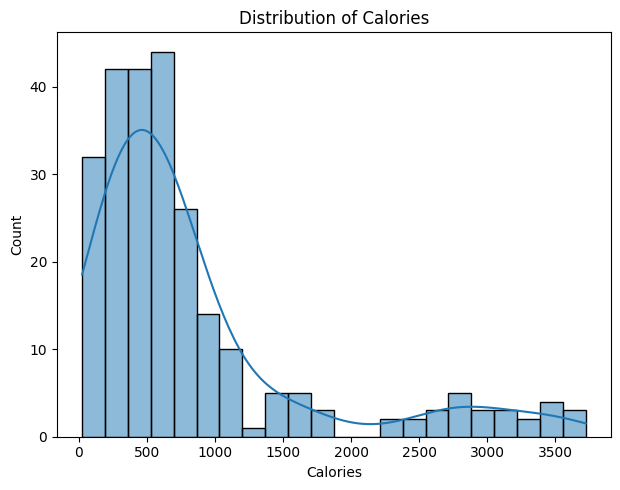

In [4]:
# Exploring the distribution of food types and nutritional values
plt.figure(figsize=(12, 5))

# Distribution of calories
plt.subplot(1, 2, 1)
sns.histplot(metadata_df['total_calories'], kde=True)
plt.title('Distribution of Calories')
plt.xlabel('Calories')


plt.tight_layout()
plt.show()

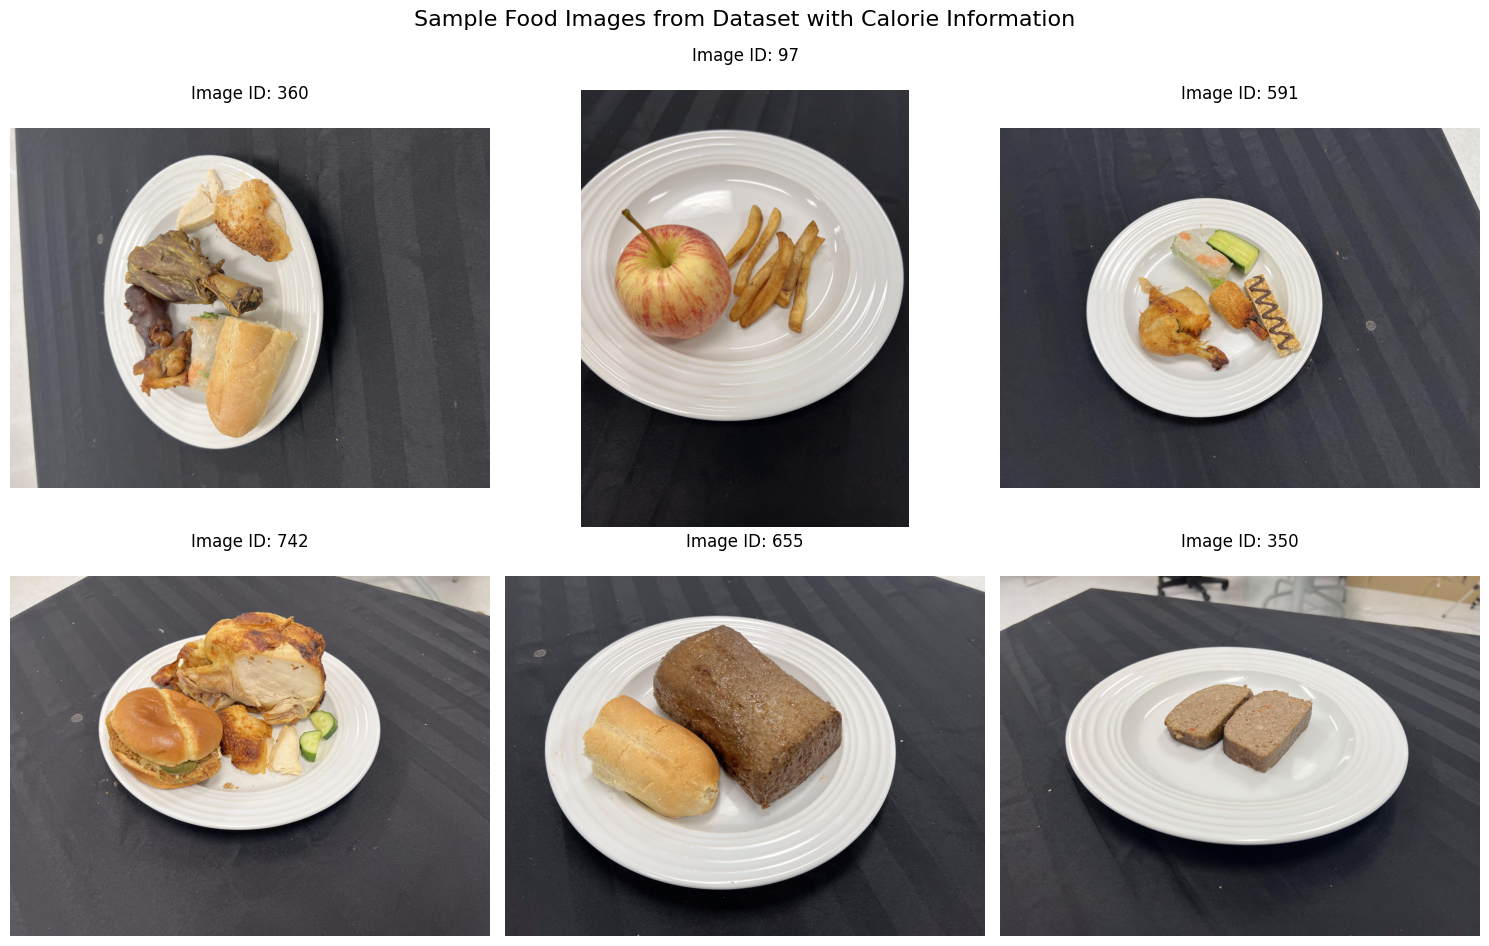

In [5]:
from PIL import Image
import numpy as np
import random

# Display sample images from the dataset
import matplotlib.pyplot as plt

# Select 6 random image IDs from the mapping
sample_image_ids = random.sample(list(image_id_to_filename.keys()), 6)

# Create a figure to display the images
plt.figure(figsize=(15, 10))

# Loop through the selected image IDs and display each image
for i, img_id in enumerate(sample_image_ids):
    # Get the filename for this image ID
    filename = image_id_to_filename[img_id]
    
    # Construct the full path to the image
    img_path = os.path.join(images_path, filename)
    
    # Try to find the corresponding metadata (calorie info)
    img_metadata = None
    for idx, row in metadata_df.iterrows():
        if 'image_id' in row and row['image_id'] == img_id:
            img_metadata = row
            break
    
    # Load and display the image
    try:
        img = Image.open(img_path)
        plt.subplot(2, 3, i+1)
        plt.imshow(np.array(img))
        
        # Add title with food type and calories if available
        title = f"Image ID: {img_id}\n"
        if img_metadata is not None and 'total_calories' in img_metadata:
            title += f"Calories: {img_metadata['total_calories']:.1f} kcal\n"
        if img_metadata is not None and 'food_item_type_1' in img_metadata:
            title += f"Food: {img_metadata['food_item_type_1']}"
            
        plt.title(title)
        plt.axis('off')
    except Exception as e:
        plt.subplot(2, 3, i+1)
        plt.text(0.5, 0.5, f"Error loading image:\n{str(e)}", 
                 horizontalalignment='center', verticalalignment='center')
        plt.axis('off')

plt.tight_layout()
plt.suptitle("Sample Food Images from Dataset with Calorie Information", fontsize=16)
plt.subplots_adjust(top=0.9)
plt.show()

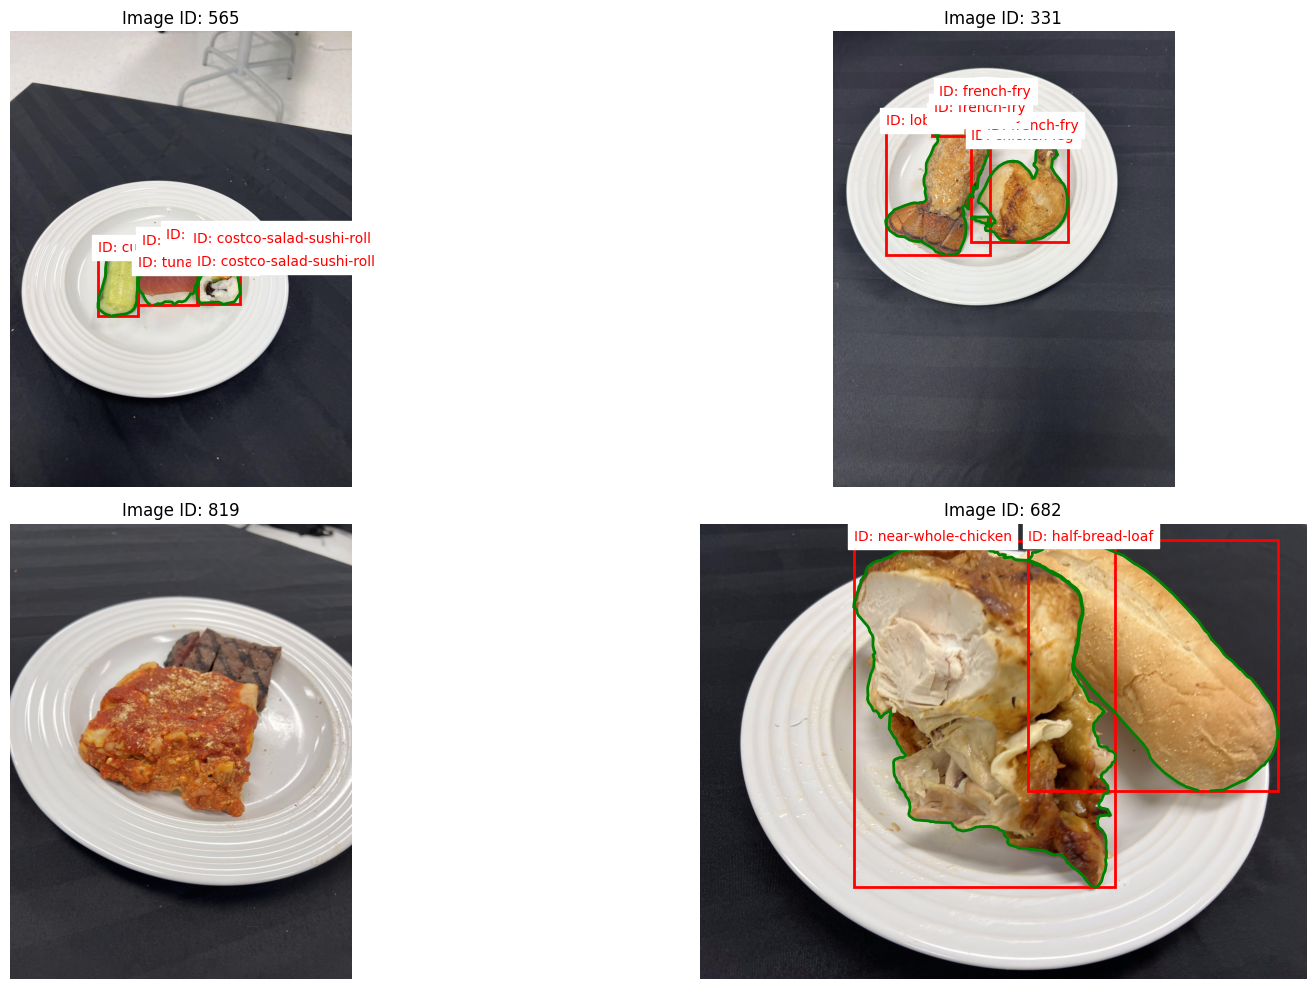

In [6]:
annotation = coco_data['annotations']
category = coco_data['categories']
#each annotation consist of id, image_id, category_id, bbox, area, and segmentation(array of array )

for a in annotation:
    a['category'] = category[a['category_id']]['name']

import matplotlib.patches as patches

# Function to visualize image segmentation with labels
def visualize_segmentation_with_labels(image_ids, coco_data, image_id_to_filename, images_path):
    plt.figure(figsize=(20, 10))
    
    for i, img_id in enumerate(image_ids):
        # Get the filename for this image ID
        filename = image_id_to_filename[img_id]
        img_path = os.path.join(images_path, filename)
        
        # Load the image
        img = Image.open(img_path)
        
        # Get annotations for this image
        annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
        
        # Plot the image
        ax = plt.subplot(2, 2, i + 1)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Image ID: {img_id}")
        
        # Add bounding boxes, segmentation, and labels
        for ann in annotations:
            bbox = ann['bbox']
            segmentation = ann['segmentation']
            category = ann['category']
            
            # Draw bounding box
            rect = patches.Rectangle(
                (bbox[0], bbox[1]), bbox[2], bbox[3],
                linewidth=2, edgecolor='r', facecolor='none'
            )
            ax.add_patch(rect)
            
            # Add label for category_id
            ax.text(
                bbox[0], bbox[1] - 5, f"ID: {category}",
                color='red', fontsize=10, backgroundcolor='white'
            )
            
            # Draw segmentation (if available)
            for seg in segmentation:
                poly = np.array(seg).reshape((-1, 2))
                ax.plot(poly[:, 0], poly[:, 1], 'g-', linewidth=2)
    
    plt.tight_layout()
    plt.show()

# Select 4 random image IDs
selected_image_ids = random.sample(list(image_id_to_filename.keys()), 4)

# Visualize segmentation with labels
visualize_segmentation_with_labels(selected_image_ids, coco_data, image_id_to_filename, images_path)

In [7]:
# align metadata df with the images
# Extract file names from COCO dataset and create mapping to dish_id
image_files = os.listdir(images_path)
valid_images = []
image_dish_ids = {}

# Map images to dish_id based on filename pattern (dish_XX_...)
for filename in image_files:
    if filename.startswith('dish_'):
        try:
            # Extract dish_id from filename
            parts = filename.split('_')
            if len(parts) > 1:
                dish_id = int(parts[1])
                if dish_id not in image_dish_ids:
                    image_dish_ids[dish_id] = []
                image_dish_ids[dish_id].append(filename)
                valid_images.append(True)
            else:
                valid_images.append(False)
        except (ValueError, IndexError):
            valid_images.append(False)
    else:
        valid_images.append(False)

# Create a new column for image paths in metadata_df
metadata_df['image_names'] = metadata_df['dish_id'].apply(
    lambda dish_id: image_dish_ids.get(dish_id, [])
)

# Add a flag indicating if valid images were found
metadata_df['valid_image'] = metadata_df['image_names'].apply(lambda x: len(x) > 0)

# Print summary
print(f"Found valid images for {metadata_df['valid_image'].sum()} out of {len(metadata_df)} dishes")
print(f"Total images mapped: {sum(len(imgs) for imgs in image_dish_ids.values())}")

# Display dishes without valid images
if not all(metadata_df['valid_image']):
    print("\nDishes without mapped images:")
    print(metadata_df[~metadata_df['valid_image']]['dish_id'].tolist())
print(metadata_df.iloc[23]['image_names'])
print(type(metadata_df.iloc[23]['image_names']))
# Remove rows without valid images
metadata_df = metadata_df[metadata_df['valid_image']]

# Reset the index after filtering
metadata_df.reset_index(drop=True, inplace=True)

# Print the updated metadata_df
print(f"Updated metadata_df with {len(metadata_df)} rows containing valid images.")
metadata_df.head()

Found valid images for 225 out of 251 dishes
Total images mapped: 889

Dishes without mapped images:
[1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 53, 54, 66, 151, 152, 171]
['dish_24_IMG_5751_jpeg.rf.af188e42b0b38829e53fc1f6421d24c8.jpg', 'dish_24_IMG_5754_jpeg.rf.095f8d99a8136a5c2dd927593356c9f4.jpg', 'dish_24_IMG_5765_jpeg.rf.9beea5446eba06ffa3775697cbc58ba7.jpg', 'dish_24_IMG_5773_jpeg.rf.2169c716b648c89c817b81be74b50cbe.jpg']
<class 'list'>
Updated metadata_df with 225 rows containing valid images.


,dish_id,total_food_weight,total_calories,total_fats,total_carbohydrates,total_protein,total_calcium,total_iron,total_magnesium,total_potassium,...,protein(g)_7,calcium(mg)_7,iron(mg)_7,magnesium(mg)_7,potassium(mg)_7,sodium(mg)_7,vitamin_d(µg)_7,vitamin_b12(µg)_7,image_names,valid_image
0,2,127.0,186.99,1.866200,21.160300,19.890200,0.114610,0.001804,0.05289,0.240500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_2_IMG_7112_jpeg.rf.5b7a5ff7e75bd9478a577...,True
1,21,399.0,352.29,29.611129,14.391865,73.686476,0.880435,0.003820,0.11859,0.798978,...,0.1755,0.00432,0.000076,0.00351,0.03969,0.00054,0.0,0.0,[dish_21_IMG_7136_jpeg.rf.6bbcb96c19d5663c8e5e...,True
2,23,266.0,659.68,36.202600,0.000000,78.815800,0.021280,0.009470,0.06916,0.861840,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_23_IMG_5706_jpeg.rf.ee6d76932000d6ed3ef4...,True
3,24,302.0,674.44,36.289000,3.448800,79.150600,0.033160,0.009578,0.07348,0.977040,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[dish_24_IMG_5751_jpeg.rf.af188e42b0b38829e53f...,True
4,25,181.0,75.72,0.116100,5.821300,12.298500,0.025640,0.000254,0.01845,0.296490,...,0.1755,0.00432,0.000076,0.00351,0.03969,0.00054,0.0,0.0,[dish_25_IMG_5801_jpeg.rf.7ea07c9740c3123110b4...,True


# Training the data

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import numpy as np
import os
from PIL import Image

# Set paths
dataset_path = 'nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images'
metadata_df

# Preprocess images and labels
image_size = (1024, 1024)  # Resize images to 128x128
images = []
labels = []

for _, row in metadata_df.iterrows():
    image_path_array = row['image_names'] # read array of image
    for name in image_path_array:
        image_path = os.path.join(dataset_path, name)  
        if os.path.exists(image_path):
            try:
                img = Image.open(image_path).resize(image_size)
                images.append(np.array(img) / 255.0)  # Normalize pixel values
                labels.append(row['total_calories'])  # Assuming 'total_calories' column exists
            except Exception as e:
                print(f"Error loading image {image_path}: {e}")

images = np.array(images)
labels = np.array(labels)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)


# Build a raw CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(1024, 1024, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((4, 4)),
    Conv2D(256, (3, 3), activation='relu'),
    MaxPooling2D((4, 4)),
    Conv2D(512, (3, 3), activation='relu'),
    MaxPooling2D((4, 4)),
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1)  # Single output for calorie prediction
])

# Display model summary
model.summary()

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test))

# Evaluate the model
loss, mae = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss}, Test MAE: {mae}")

# Save the model
model.save('food_calorie_cnn_model.h5')


In [10]:
# Predict calories for new images
def predict_calories(image_path):
    img = Image.open(image_path).resize(image_size)
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    prediction = model.predict(img_array)
    return prediction[0][0]

# Example usage
example_image_path = 'nutritionverse-data/nutritionverse-manual/nutritionverse-manual/images/dish_2_IMG_7112_jpeg.rf.5b7a5ff7e75bd9478a577d1ab0c87dcc.jpg'
predicted_calories = predict_calories(example_image_path)
print(f"Predicted Calories: {predicted_calories:.2f} kcal")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Calories: 1123.66 kcal
